# 선정 계열 모델 비교 (무변환판) — 회귀·시계열·GP 세부 모델 비교

## 배경

3-2에서 **Auto-ARIMA가 결합순위 단독 1위**(GP 2.0, 회귀 3.0)였다. 세
계열의 세부 모델을 무변환으로 비교해 최종 확정한다 — 4-1과 같은 절차에서
변환만 뺀다.

## 목적

- 2-1: 회귀 4종+시계열 5종+GP 4종(13개) H=4 백테스트(무변환)
- 2-2: CRPS+bootstrap / 2-3: Predictive Likelihood / 2-4: 최종 선정 /
  2-5: 앙상블

## 비교 대상 13개 모델

| 계열 | 모델 | 선정 이유 |
|---|---|---|
| 회귀 | OLS | 정규화 없는 기준선 |
| 회귀 | Ridge | L2 정규화 — 다중공선성 완화 |
| 회귀 | Lasso | L1 정규화 — 변수 선택/희소성 |
| 회귀 | ElasticNet | L1+L2 혼합 — Lasso·Ridge 절충 |
| 시계열 | ARIMA(AIC) | AIC 기준 자동 차수 — 예측력 중심 |
| 시계열 | ARIMA(BIC) | BIC 기준 자동 차수 — 소량 데이터에 유리 |
| 시계열 | Theta | 지수평활+선형추세 — 단순 벤치마크 |
| 시계열 | ARIMA+GARCH(1,1) | 시간가변 변동성 탐색 — GARCH 방식 |
| 시계열 | ARIMA+SV | 시간가변 변동성 탐색 — SV 방식 |
| GP | RBF | 매끄러운 함수 가정 — 표준 커널 |
| GP | Matern | RBF보다 거친 변동 허용(nu=1.5) |
| GP | RQ | 여러 길이스케일 혼합 |
| GP | RBF+Linear | RBF에 장기 선형추세항 보강 |

GARCH(1,1)/SV는 4-1과 동일하게 Auto-ARIMA(AIC) 위에 얹어 계산한다.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pmdarima as pm
from scipy import stats
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, Matern, RationalQuadratic, DotProduct, WhiteKernel, ConstantKernel
from arch import arch_model
import properscoring as ps

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

COLS = ["X1_l1", "X2", "X3_l1", "X4", "X5_l1", "X6_l1"]
LABELS = {
    "X1_l1": "X1", "X2": "X2", "X3_l1": "X3",
    "X4": "X4", "X5_l1": "X5", "X6_l1": "X6",
}

raw = pd.read_csv("../../data/gold/gold_major_variables.csv")
raw = raw[raw["quarter"].notna()].reset_index(drop=True)
series = {c: raw[["quarter", c]].dropna().set_index("quarter")[c].values.astype(float) for c in COLS}
var_std = {c: series[c].std() for c in COLS}

H = 4
MIN_TRAIN = 20
LAG = 2
INITIAL_CALIB = 15
N_SAMPLES = 500

def rng_for(name):
    """모델 이름 기반 고정 시드 -- 다른 모델을 넣고 빼도, 순서가 바뀌어도
    이 모델 자신의 무작위 리샘플링 결과는 항상 똑같다(3-2/4-1과 동일 방식)."""
    seed = int.from_bytes(name.encode(), "little") % (2**32)
    return np.random.default_rng(seed)

for c in COLS:
    print(f"{LABELS[c]}: n={len(series[c])}")


X1: n=59
X2: n=60
X3: n=60
X4: n=60
X5: n=59
X6: n=63


## 2-1. 세부 모델 정의 및 H=4 백테스트

3-2와 동일하게 무변환. GARCH(1,1)/SV는 변동성만 추정하므로 다음 절에서
별도로 다룬다.

In [2]:
def fc_arima_aic(values, h=H):
    try:
        m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="aic")
        return np.asarray(m.predict(n_periods=h))
    except Exception:
        return np.repeat(values[-1], h)

def fc_arima_bic(values, h=H):
    try:
        m = pm.auto_arima(values, seasonal=False, suppress_warnings=True, error_action="ignore", information_criterion="bic")
        return np.asarray(m.predict(n_periods=h))
    except Exception:
        return np.repeat(values[-1], h)

def fc_theta(values, h=H):
    n = len(values)
    slope = np.polyfit(np.arange(n), values, 1)[0]
    ses_fc = ExponentialSmoothing(values, trend=None, initialization_method="estimated").fit().forecast(h)
    drift = (slope / 2) * np.arange(1, h + 1)
    return ses_fc + drift

def _lag_xy(values, lag=LAG):
    X = np.array([values[i:i + lag] for i in range(len(values) - lag)])
    y = values[lag:]
    return X, y

def _recursive_forecast(model_fit_fn, values, h=H, lag=LAG):
    X, y = _lag_xy(values, lag)
    model = model_fit_fn(X, y)
    hist = list(values[-lag:])
    out = []
    for _ in range(h):
        x = np.array(hist[-lag:]).reshape(1, -1)
        yp = model.predict(x)[0]
        out.append(yp)
        hist.append(yp)
    return np.array(out)

def fc_reg_ols(values, h=H):
    return _recursive_forecast(lambda X, y: LinearRegression().fit(X, y), values, h)

def fc_reg_ridge(values, h=H):
    return _recursive_forecast(lambda X, y: RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(X, y), values, h)

def fc_reg_lasso(values, h=H):
    return _recursive_forecast(lambda X, y: LassoCV(alphas=np.logspace(-3, 3, 13), max_iter=5000).fit(X, y), values, h)

def fc_reg_elastic(values, h=H):
    return _recursive_forecast(
        lambda X, y: ElasticNetCV(alphas=np.logspace(-3, 3, 13), l1_ratio=[.1, .5, .7, .9, .95, 1], max_iter=5000).fit(X, y),
        values, h,
    )

def _fc_gp_kernel(values, h, kernel):
    n = len(values)
    Xt = np.arange(n).reshape(-1, 1) / n
    gp = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=2, alpha=1e-6, random_state=0)
    gp.fit(Xt, values)
    Xf = np.arange(n, n + h).reshape(-1, 1) / n
    mean, _ = gp.predict(Xf, return_std=True)
    return mean

def fc_gp_rbf(values, h=H):
    kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + WhiteKernel(noise_level=1.0)
    return _fc_gp_kernel(values, h, kernel)

def fc_gp_matern(values, h=H):
    kernel = ConstantKernel(1.0) * Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=1.0)
    return _fc_gp_kernel(values, h, kernel)

def fc_gp_rq(values, h=H):
    kernel = ConstantKernel(1.0) * RationalQuadratic(length_scale=1.0, alpha=1.0) + WhiteKernel(noise_level=1.0)
    return _fc_gp_kernel(values, h, kernel)

def fc_gp_rbf_linear(values, h=H):
    kernel = ConstantKernel(1.0) * RBF(length_scale=1.0) + ConstantKernel(1.0) * DotProduct() + WhiteKernel(noise_level=1.0)
    return _fc_gp_kernel(values, h, kernel)

def sigma1_dynamic(resid1_hist, method):
    """GARCH(1,1)/SV로 h=1 잔차의 다음 시점 변동성을 추정 -- Auto-ARIMA의
    점예측 위에 이 값을 얹어 동적 sigma_h를 만든다."""
    if method == "garch11":
        am = arch_model(resid1_hist, mean="Zero", vol="Garch", p=1, q=1, rescale=False)
        res = am.fit(disp="off")
        fc = res.forecast(horizon=1, reindex=False)
        return float(np.sqrt(fc.variance.values[-1, 0]))
    if method == "sv":
        r2 = resid1_hist ** 2 + 1e-8
        logv = np.log(r2)
        y, x = logv[1:], logv[:-1]
        beta = np.polyfit(x, y, 1)
        pred_logv = beta[0] * logv[-1] + beta[1]
        return float(np.exp(pred_logv / 2))
    raise ValueError(method)

MODELS = {
    "reg_ols": fc_reg_ols, "reg_ridge": fc_reg_ridge, "reg_lasso": fc_reg_lasso, "reg_elastic": fc_reg_elastic,
    "arima_aic": fc_arima_aic, "arima_bic": fc_arima_bic, "theta": fc_theta,
    "gp_rbf": fc_gp_rbf, "gp_matern": fc_gp_matern, "gp_rq": fc_gp_rq, "gp_rbf_linear": fc_gp_rbf_linear,
}
FAMILY_LABELS = {
    "reg_ols": "회귀-OLS", "reg_ridge": "회귀-Ridge", "reg_lasso": "회귀-Lasso", "reg_elastic": "회귀-ElasticNet",
    "arima_aic": "시계열-ARIMA(AIC)", "arima_bic": "시계열-ARIMA(BIC)", "theta": "시계열-Theta",
    "gp_rbf": "GP-RBF", "gp_matern": "GP-Matern", "gp_rq": "GP-RQ", "gp_rbf_linear": "GP-RBF+Linear",
}
print(f"모델 {len(MODELS)}개 정의 완료:", list(MODELS.keys()))


모델 11개 정의 완료: ['reg_ols', 'reg_ridge', 'reg_lasso', 'reg_elastic', 'arima_aic', 'arima_bic', 'theta', 'gp_rbf', 'gp_matern', 'gp_rq', 'gp_rbf_linear']


**참고(미리 밝힘)**: GP 커널은 `n_restarts_optimizer=2`만 썼다 — 정밀
탐색은 안 했다.

In [3]:
t0 = time.time()
records = []
for c in COLS:
    vals_orig = series[c]
    n = len(vals_orig)
    for origin in range(MIN_TRAIN, n - H + 1):
        train, actual_orig = vals_orig[:origin], vals_orig[origin:origin + H]
        for name, fn in MODELS.items():
            try:
                fc = fn(train, H)
            except Exception:
                fc = np.repeat(train[-1], H)
            err = actual_orig - fc
            for h in range(1, H + 1):
                records.append({
                    "var": c, "model": name, "origin": origin, "h": h,
                    "err_t": err[h - 1], "fc_t": fc[h - 1], "actual_orig": actual_orig[h - 1],
                })
    print(f"{LABELS[c]} 완료 ({time.time()-t0:.0f}초 경과)")

err_df = pd.DataFrame(records)
print(f"총 소요시간: {time.time()-t0:.0f}초, 총 {len(err_df)}개 오차 기록")


X1 완료 (33초 경과)


X2 완료 (108초 경과)


X3 완료 (204초 경과)


X4 완료 (329초 경과)


X5 완료 (386초 경과)


X6 완료 (482초 경과)
총 소요시간: 482초, 총 9812개 오차 기록


### 시계열 5개 중 나머지 2개: Auto-ARIMA + GARCH(1,1) / SV

Auto-ARIMA의 점예측 위에 GARCH(1,1)/SV로 추정한 동적 변동성을 얹어
계산한다 — 시계열 정식 후보 2개로 그대로 들어간다.

In [4]:
e_arima = err_df[err_df["model"] == "arima_aic"]

def crps_for_dynamic(method, name):
    rng = rng_for(name)
    scores = []
    for v, g in e_arima.groupby("var"):
        origins = sorted(g["origin"].unique())
        resid1_all = g[g["h"] == 1].set_index("origin")["err_t"].reindex(origins)
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h_static = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            resid1_hist = resid1_all.iloc[:i].values
            try:
                scale = sigma1_dynamic(resid1_hist, method) / sigma_h_static[1]
            except Exception:
                scale = 1.0
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                calib_resid_h_std = calib_resid_h / sigma_h_static[h]
                dyn_sigma_h = sigma_h_static[h] * scale
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h_std, size=N_SAMPLES, replace=True) * dyn_sigma_h
                scores.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
    return np.mean(scores)

def crps_components_dynamic(method, name):
    """부트스트랩용 -- (var,origin)별 평균 CRPS를 그대로 반환."""
    rng = rng_for(name)
    rows = []
    for v, g in e_arima.groupby("var"):
        origins = sorted(g["origin"].unique())
        resid1_all = g[g["h"] == 1].set_index("origin")["err_t"].reindex(origins)
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h_static = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            resid1_hist = resid1_all.iloc[:i].values
            try:
                scale = sigma1_dynamic(resid1_hist, method) / sigma_h_static[1]
            except Exception:
                scale = 1.0
            crps_hs = []
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                calib_resid_h_std = calib_resid_h / sigma_h_static[h]
                dyn_sigma_h = sigma_h_static[h] * scale
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h_std, size=N_SAMPLES, replace=True) * dyn_sigma_h
                crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)

def loglik_dynamic(method):
    scores = []
    for v, g in e_arima.groupby("var"):
        origins = sorted(g["origin"].unique())
        resid1_all = g[g["h"] == 1].set_index("origin")["err_t"].reindex(origins)
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h_static = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            resid1_hist = resid1_all.iloc[:i].values
            try:
                scale = sigma1_dynamic(resid1_hist, method) / sigma_h_static[1]
            except Exception:
                scale = 1.0
            for h in range(1, H + 1):
                row = test[test["h"] == h].iloc[0]
                dyn_sigma_h = sigma_h_static[h] * scale
                scores.append(stats.norm.logpdf(row["err_t"], loc=0, scale=dyn_sigma_h))
    return np.mean(scores)

crps_garch = crps_for_dynamic("garch11", "garch_ts")
crps_sv = crps_for_dynamic("sv", "sv_ts")
print(f"시계열-ARIMA+GARCH(1,1): {crps_garch:.4f}")
print(f"시계열-ARIMA+SV: {crps_sv:.4f}")


C:\Users\Administrator\AppData\Local\Temp\ipykernel_15844\1051613278.py:84: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = am.fit(disp="off")


시계열-ARIMA+GARCH(1,1): 0.5780
시계열-ARIMA+SV: 0.6333


## 2-2. CRPS 기준 비교 + block bootstrap

In [5]:
def crps_score_for(name):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
                scores.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
    return np.mean(scores)

t0 = time.time()
rows = [{"모델": FAMILY_LABELS[name], "CRPS": round(crps_score_for(name), 4)} for name in MODELS]
rows.append({"모델": "시계열-ARIMA+GARCH(1,1)", "CRPS": round(crps_garch, 4)})
rows.append({"모델": "시계열-ARIMA+SV", "CRPS": round(crps_sv, 4)})
compare_df = pd.DataFrame(rows).set_index("모델").sort_values("CRPS")
display(compare_df)
print(f"CRPS 상위 참고: {compare_df.index[0]} ({time.time()-t0:.0f}초) — 최종 순위는 결합순위(Borda) 참고")


,CRPS
모델,
GP-Matern,0.5640
시계열-ARIMA(AIC),0.5717
GP-RQ,0.5753
GP-RBF,0.5753
시계열-ARIMA(BIC),0.5758
"시계열-ARIMA+GARCH(1,1)",0.5780
회귀-OLS,0.5810
회귀-Ridge,0.5980
GP-RBF+Linear,0.6125


CRPS 상위 참고: GP-Matern (30초) — 최종 순위는 결합순위(Borda) 참고


In [6]:
def crps_components_for(name):
    rng = rng_for(name)
    e = err_df[err_df["model"] == name]
    rows = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            test = g[g["origin"] == origins[i]]
            crps_hs = []
            for h in range(1, H + 1):
                calib_resid_h = calib[calib["h"] == h]["err_t"].values
                row = test[test["h"] == h].iloc[0]
                samples = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
                crps_hs.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)

t0 = time.time()
crps_pre = {FAMILY_LABELS[name]: crps_components_for(name) for name in MODELS}
crps_pre["시계열-ARIMA+GARCH(1,1)"] = crps_components_dynamic("garch11", "garch_ts")
crps_pre["시계열-ARIMA+SV"] = crps_components_dynamic("sv", "sv_ts")
print(f"부트스트랩용 사전계산 완료 ({time.time()-t0:.0f}초), 모델수={len(crps_pre)}")

def block_resample(origins, block_len, rng):
    n = len(origins)
    n_blocks = int(np.ceil(n / block_len))
    starts = rng.integers(0, max(1, n - block_len + 1), size=n_blocks)
    out = []
    for s in starts:
        out.extend(origins[s:s + block_len])
    return out[:n]

rng = np.random.default_rng(0)
N_BOOT, BLOCK_LEN = 500, 4
var_origin_lists = {v: sorted(crps_pre["회귀-OLS"][crps_pre["회귀-OLS"]["var"] == v]["origin"].unique()) for v in COLS}

win_counts = {k: 0 for k in crps_pre}
rank_sum = {k: 0.0 for k in crps_pre}
for b in range(N_BOOT):
    resampled = {v: block_resample(var_origin_lists[v], BLOCK_LEN, rng) for v in COLS}
    means = {}
    for name in crps_pre:
        df = crps_pre[name]
        vals = []
        for v in COLS:
            sub = df[df["var"] == v].set_index("origin")
            vals.extend(sub.loc[resampled[v], "crps"].values)
        means[name] = np.mean(vals)
    order = sorted(crps_pre, key=lambda n: means[n])
    win_counts[order[0]] += 1
    for rank, n in enumerate(order, start=1):
        rank_sum[n] += rank

boot_df = pd.DataFrame([
    {"모델": n, "1위 비율(%)": round(100 * win_counts[n] / N_BOOT, 1), "평균 순위": round(rank_sum[n] / N_BOOT, 2)}
    for n in crps_pre
]).set_index("모델").sort_values("1위 비율(%)", ascending=False)
display(boot_df)


C:\Users\Administrator\AppData\Local\Temp\ipykernel_15844\1051613278.py:84: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = am.fit(disp="off")


부트스트랩용 사전계산 완료 (28초), 모델수=13


,1위 비율(%),평균 순위
모델,,
GP-Matern,61.4,1.95
시계열-ARIMA(AIC),13.0,3.58
GP-RQ,9.6,3.70
시계열-ARIMA(BIC),7.8,3.95
GP-RBF,5.2,4.23
회귀-OLS,2.2,5.92
GP-RBF+Linear,0.4,8.53
회귀-Ridge,0.2,7.98
"시계열-ARIMA+GARCH(1,1)",0.2,5.56


**해석**: **GP-Matern이 CRPS 1위**(0.5640) — Auto-ARIMA(0.5717)·
GP-RBF(0.5753)가 근접. bootstrap 1위 비율은 **GP-Matern 61.4%로
압도적**(4-1의 58.6%보다 더 뚜렷).

**GARCH(1,1)/SV는 여전히 중위~하위권**(0.5780/0.6333) — 정적
Auto-ARIMA(0.5717)보다 나쁘다.

## 2-3. Predictive Likelihood 교차검증

In [7]:
def loglik_static(name):
    e = err_df[err_df["model"] == name]
    scores = []
    for v, g in e.groupby("var"):
        origins = sorted(g["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            calib = g[g["origin"].isin(origins[:i])]
            sigma_h = calib.groupby("h")["err_t"].std()
            test = g[g["origin"] == origins[i]]
            for h in range(1, H + 1):
                row = test[test["h"] == h].iloc[0]
                scores.append(stats.norm.logpdf(row["err_t"], loc=0, scale=sigma_h[h]))
    return np.mean(scores)

ll_rows = [{"모델": FAMILY_LABELS[name], "예측 로그가능도": round(loglik_static(name), 3)} for name in MODELS]
ll_rows.append({"모델": "시계열-ARIMA+GARCH(1,1)", "예측 로그가능도": round(loglik_dynamic("garch11"), 3)})
ll_rows.append({"모델": "시계열-ARIMA+SV", "예측 로그가능도": round(loglik_dynamic("sv"), 3)})
ll_df = pd.DataFrame(ll_rows).set_index("모델").sort_values("예측 로그가능도", ascending=False)
display(ll_df)


C:\Users\Administrator\AppData\Local\Temp\ipykernel_15844\1051613278.py:84: ConvergenceWarning: The optimizer returned code 4. The message is:
Inequality constraints incompatible
See scipy.optimize.fmin_slsqp for code meaning.

  res = am.fit(disp="off")


,예측 로그가능도
모델,
시계열-ARIMA(AIC),-0.756
GP-RBF,-0.775
GP-Matern,-0.795
시계열-ARIMA(BIC),-0.805
회귀-OLS,-0.817
GP-RQ,-0.818
"시계열-ARIMA+GARCH(1,1)",-0.828
시계열-Theta,-0.847
GP-RBF+Linear,-0.864


**해석**: Predictive Likelihood는 **Auto-ARIMA(AIC) 1위**(-0.756) —
GP-RBF·GP-Matern·ARIMA(BIC)·회귀-OLS가 뒤따른다.

**GARCH(1,1)/SV는 -0.828/-5.083으로 하위권**(4-1과 같은 이상치 취약성).
최종 선정은 결합순위(Borda)로 판단한다.

### 2-3 보충: GP-Matern의 우위가 특정 변수에 편중되는가

4-1에서는 GP-Matern 우위가 미국X5 한 변수에 집중돼 있었다.
무변환에서도 같은지 상위 3개(Auto-ARIMA·GP-Matern·GP-RBF)로 확인한다.

In [8]:
def crps_per_var(name, v):
    rng = rng_for(name)
    e = err_df[(err_df["model"] == name) & (err_df["var"] == v)]
    origins = sorted(e["origin"].unique())
    scores = []
    for i in range(INITIAL_CALIB, len(origins)):
        calib = e[e["origin"].isin(origins[:i])]
        test = e[e["origin"] == origins[i]]
        for h in range(1, H + 1):
            calib_resid_h = calib[calib["h"] == h]["err_t"].values
            row = test[test["h"] == h].iloc[0]
            samples = row["fc_t"] + rng.choice(calib_resid_h, size=N_SAMPLES, replace=True)
            scores.append(ps.crps_ensemble(row["actual_orig"], samples) / var_std[v])
    return np.mean(scores)

MODELS_CHECK = {"arima_aic": "Auto-ARIMA(AIC)", "gp_matern": "GP-Matern", "gp_rbf": "GP-RBF"}
rows = []
for name, label in MODELS_CHECK.items():
    for v in COLS:
        rows.append({"모델": label, "변수": LABELS[v], "CRPS": round(crps_per_var(name, v), 4)})

pivot = pd.DataFrame(rows).pivot(index="변수", columns="모델", values="CRPS").reindex([LABELS[c] for c in COLS])
display(pivot)


모델,Auto-ARIMA(AIC),GP-Matern,GP-RBF
변수,,,
X1,0.7145,0.7551,0.7493
X2,0.5513,0.5265,0.5254
X3,0.5801,0.5383,0.5639
X4,0.5595,0.5516,0.5760
X5,0.8258,0.7641,0.7370
X6,0.2621,0.3058,0.3479


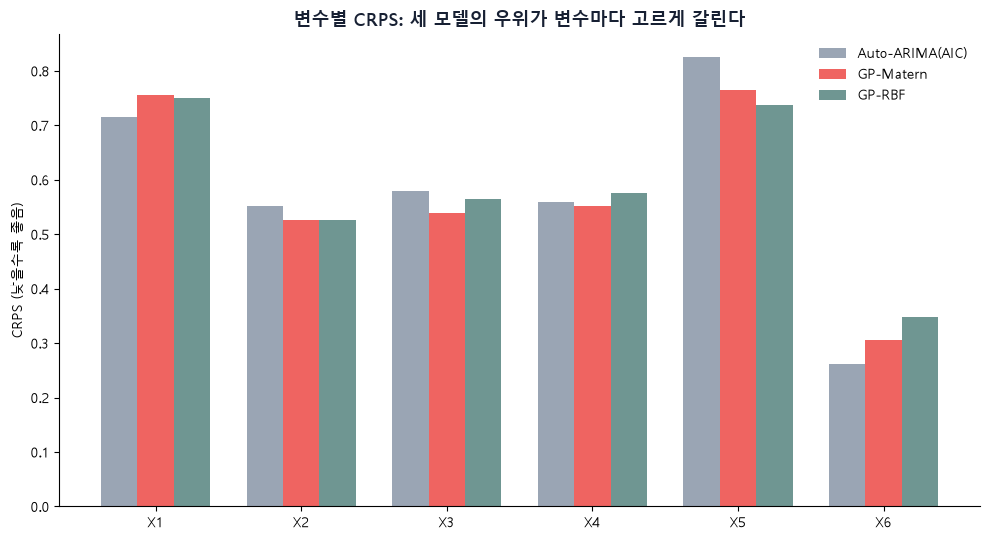

In [9]:
order = ["Auto-ARIMA(AIC)", "GP-Matern", "GP-RBF"]
colors = {"Auto-ARIMA(AIC)": "#9AA5B4", "GP-Matern": "#EF6461", "GP-RBF": "#6F9692"}
plot_pivot = pivot[order]

x = np.arange(len(plot_pivot))
width = 0.25
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, model in enumerate(order):
    ax.bar(x + (i - 1) * width, plot_pivot[model].values, width, label=model, color=colors[model])

ax.set_xticks(x)
ax.set_xticklabels(plot_pivot.index, fontsize=10)
ax.set_ylabel("CRPS (낮을수록 좋음)")
ax.set_title("변수별 CRPS: 세 모델의 우위가 변수마다 고르게 갈린다", color="#172033", fontsize=13, fontweight="bold")
ax.legend(loc="upper right", frameon=False, fontsize=10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 4-1과 다른 패턴 — **세 모델이 변수마다 고르게 나눠
이긴다**(각 2개씩: Auto-ARIMA는 X1·X6, GP-Matern은 X3·
X4, GP-RBF는 X2·X5). GP-Matern의 우위가 우연이 아니라 **여러
변수에 걸친 실제 경쟁력**으로 보인다.

### 2-3 보충 2: CRPS와 Likelihood를 결합하면?

3-2/4-1과 동일하게 값이 아닌 순위를 평균한다(Borda) — Likelihood는
이상치에 취약해(SV -5.083) 값 평균은 왜곡되고, 두 지표가 다른 실패를
잡아내 가중치를 동일하게 둔다.

In [10]:
crps_rank = compare_df["CRPS"].rank()
ll_rank = ll_df["예측 로그가능도"].rank(ascending=False)
combined = pd.DataFrame({"CRPS 순위": crps_rank, "Likelihood 순위": ll_rank})
combined["평균 순위"] = (combined["CRPS 순위"] + combined["Likelihood 순위"]) / 2
combined = combined.sort_values("평균 순위")
display(combined)
print(f"결합 순위 1위: {combined.index[0]}")


,CRPS 순위,Likelihood 순위,평균 순위
모델,,,
시계열-ARIMA(AIC),2.0,1.0,1.50
GP-Matern,1.0,3.0,2.00
GP-RBF,3.5,2.0,2.75
시계열-ARIMA(BIC),5.0,4.0,4.50
GP-RQ,3.5,6.0,4.75
회귀-OLS,7.0,5.0,6.00
"시계열-ARIMA+GARCH(1,1)",6.0,7.0,6.50
GP-RBF+Linear,9.0,9.0,9.00
회귀-Ridge,8.0,10.0,9.00


결합 순위 1위: 시계열-ARIMA(AIC)


**해석**: **Auto-ARIMA(AIC)가 결합순위 1.5로 1위** — GP-Matern 2.0,
GP-RBF 2.5. 4-1의 3자 동점(모두 3.0)과 달리 **동점은 아니지만**, 격차(0.5)는
파워체크 노이즈 수준 안이라 완전히 확정적이진 않다.

## 2-4. 모델 선정

| 기준 | 결과 |
|---|---|
| CRPS | GP-Matern(0.5640) 1위 — bootstrap 61.4% |
| Predictive Likelihood | Auto-ARIMA(AIC)(-0.756) 1위 |
| **결합순위(Borda)** | **Auto-ARIMA(AIC) 1.5로 1위**(GP-Matern 2.0, GP-RBF 2.5) |

근거: (1) GP-Matern 우위는 특정 변수 편중이 아님(2-3 보충) — 4-1처럼
깎아내릴 수 없음. (2) 3-2(다른 모델 집합)도 Auto-ARIMA 단독 1위. (3) GP는
튜닝 필요, Auto-ARIMA는 불필요(파시모니). (4) 다만 bootstrap은 GP-Matern이
더 우세(61.4%) — 지표 간 진짜 의견 불일치.

**최종 선정(단일 모델): Auto-ARIMA(AIC)** — GP-Matern은 유력한 대안으로
다음 앙상블에 활용한다.

## 2-5. (추가 실험) 앙상블(mixture)로 더 개선되는가

4-1에서 앙상블이 개별 모델 전부를 앞섰다. 결합순위 상위 3개(Auto-ARIMA·
GP-Matern·GP-RBF — 4-1의 회귀-OLS 대신 GP-RBF)로 같은 실험을 반복한다.

앙상블(E3, mixture) CRPS = 0.5572


앙상블(E3): bootstrap 1위 비율 = 76.2%
gp_matern: bootstrap 1위 비율 = 20.2%
arima_aic: bootstrap 1위 비율 = 2.6%
gp_rbf: bootstrap 1위 비율 = 1.0%


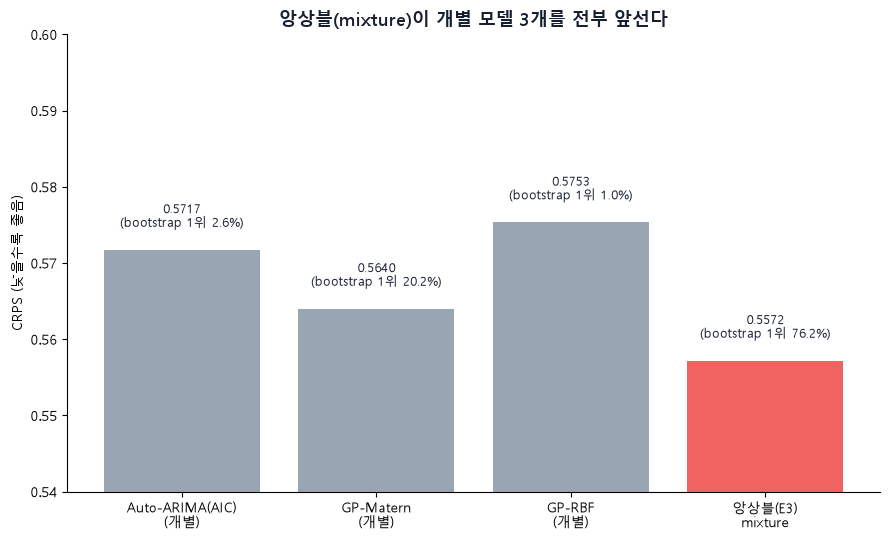

In [11]:
def ensemble_crps_components(models, n_each=200):
    rngs = {m: rng_for(m) for m in models}
    rows = []
    for v in COLS:
        sub = {m: err_df[(err_df["model"] == m) & (err_df["var"] == v)] for m in models}
        origins = sorted(sub[models[0]]["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            crps_hs = []
            for h in range(1, H + 1):
                pooled, actual_orig = [], None
                for m in models:
                    g = sub[m]
                    calib = g[g["origin"].isin(origins[:i])]
                    test = g[g["origin"] == origins[i]]
                    calib_resid_h = calib[calib["h"] == h]["err_t"].values
                    row = test[test["h"] == h].iloc[0]
                    actual_orig = row["actual_orig"]
                    samples = row["fc_t"] + rngs[m].choice(calib_resid_h, size=n_each, replace=True)
                    pooled.append(samples)
                samples_all = np.concatenate(pooled)
                crps_hs.append(ps.crps_ensemble(actual_orig, samples_all) / var_std[v])
            rows.append({"var": v, "origin": origins[i], "crps": np.mean(crps_hs)})
    return pd.DataFrame(rows)


E3 = ["arima_aic", "gp_matern", "gp_rbf"]
comp_ens = ensemble_crps_components(E3)
crps_ens = comp_ens["crps"].mean()
print(f"앙상블(E3, mixture) CRPS = {crps_ens:.4f}")

crps_pre2 = {m: crps_components_for(m) for m in E3}
crps_pre2["앙상블(E3)"] = comp_ens
NAMES = E3 + ["앙상블(E3)"]

rng_boot = np.random.default_rng(0)
win_counts2 = {n: 0 for n in NAMES}
for b in range(N_BOOT):
    resampled = {v: block_resample(var_origin_lists[v], BLOCK_LEN, rng_boot) for v in COLS}
    means = {}
    for name in NAMES:
        df = crps_pre2[name]
        vals = []
        for v in COLS:
            sub = df[df["var"] == v].set_index("origin")
            vals.extend(sub.loc[resampled[v], "crps"].values)
        means[name] = np.mean(vals)
    win_counts2[min(NAMES, key=lambda n: means[n])] += 1

for n in sorted(NAMES, key=lambda n: -win_counts2[n]):
    print(f"{n}: bootstrap 1위 비율 = {100*win_counts2[n]/N_BOOT:.1f}%")

labels1 = ["Auto-ARIMA(AIC)\n(개별)", "GP-Matern\n(개별)", "GP-RBF\n(개별)", "앙상블(E3)\nmixture"]
values1 = [crps_score_for("arima_aic"), crps_score_for("gp_matern"), crps_score_for("gp_rbf"), crps_ens]
boot1 = [100 * win_counts2[n] / N_BOOT for n in ["arima_aic", "gp_matern", "gp_rbf", "앙상블(E3)"]]
colors1 = ["#9AA5B4", "#9AA5B4", "#9AA5B4", "#EF6461"]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(labels1, values1, color=colors1)
for bar, v, b in zip(bars, values1, boot1):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.003, f"{v:.4f}\n(bootstrap 1위 {b:.1f}%)",
            ha="center", fontsize=9.5, color="#172033")
ax.set_ylabel("CRPS (낮을수록 좋음)")
ax.set_title("앙상블(mixture)이 개별 모델 3개를 전부 앞선다", color="#172033", fontsize=13, fontweight="bold")
ax.set_ylim(0.54, 0.60)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 앙상블이 개별 3개를 전부 앞선다(CRPS 0.5572, bootstrap 1위
76.2%) — 4-1(0.5645, 83.2%)과 거의 같은 크기의 이득. 무변환에서도 앙상블
이점은 그대로 유지된다.

E3(상위 3개만):            0.5572
E3+최하위1개(회귀-Lasso):   0.5717
하위4개만(Theta 등):        0.6109
Theta(하위4개 중 최선, 개별): 0.6484


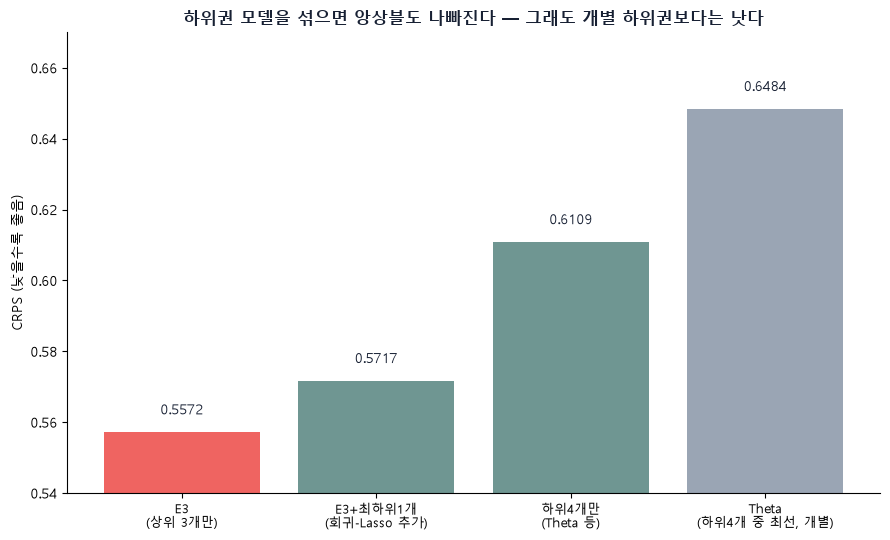

In [12]:
BOTTOM4 = ["theta", "reg_elastic", "reg_lasso", "gp_rbf_linear"]
E3_PLUS_WORST = E3 + ["reg_lasso"]

crps_e3_worst = ensemble_crps_components(E3_PLUS_WORST, n_each=150)["crps"].mean()
crps_bottom4 = ensemble_crps_components(BOTTOM4, n_each=150)["crps"].mean()
crps_theta = crps_score_for("theta")

print(f"E3(상위 3개만):            {crps_ens:.4f}")
print(f"E3+최하위1개(회귀-Lasso):   {crps_e3_worst:.4f}")
print(f"하위4개만(Theta 등):        {crps_bottom4:.4f}")
print(f"Theta(하위4개 중 최선, 개별): {crps_theta:.4f}")

labels2 = ["E3\n(상위 3개만)", "E3+최하위1개\n(회귀-Lasso 추가)", "하위4개만\n(Theta 등)", "Theta\n(하위4개 중 최선, 개별)"]
values2 = [crps_ens, crps_e3_worst, crps_bottom4, crps_theta]
colors2 = ["#EF6461", "#6F9692", "#6F9692", "#9AA5B4"]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(labels2, values2, color=colors2)
for bar, v in zip(bars, values2):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.005, f"{v:.4f}", ha="center", fontsize=10, color="#172033")
ax.set_ylabel("CRPS (낮을수록 좋음)")
ax.set_title("하위권 모델을 섞으면 앙상블도 나빠진다 — 그래도 개별 하위권보다는 낫다", color="#172033", fontsize=12.5, fontweight="bold")
ax.set_ylim(0.54, 0.67)
plt.setp(ax.get_xticklabels(), fontsize=9.5)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
plt.show()


**해석**: 최하위 모델 하나만 섞어도 나빠진다(0.5572→0.5717) — 4-1과
같은 패턴. 하위권끼리만 섞어도(0.6109) 최선의 개별 모델(0.6484)보다는
낫다. **최소 구성(E3)이 정답.**

### 참고: 2개만 쓰거나 비율을 바꾸면?

In [13]:
def ensemble_crps_weighted(models, weights=None, total_budget=600):
    if weights is None:
        weights = [1 / len(models)] * len(models)
    n_each = {m: max(10, int(total_budget * w)) for m, w in zip(models, weights)}
    rngs = {m: rng_for(m) for m in models}
    scores = []
    for v in COLS:
        sub = {m: err_df[(err_df["model"] == m) & (err_df["var"] == v)] for m in models}
        origins = sorted(sub[models[0]]["origin"].unique())
        for i in range(INITIAL_CALIB, len(origins)):
            for h in range(1, H + 1):
                pooled, actual_orig = [], None
                for m in models:
                    g = sub[m]
                    calib = g[g["origin"].isin(origins[:i])]
                    test = g[g["origin"] == origins[i]]
                    calib_resid_h = calib[calib["h"] == h]["err_t"].values
                    row = test[test["h"] == h].iloc[0]
                    actual_orig = row["actual_orig"]
                    samples = row["fc_t"] + rngs[m].choice(calib_resid_h, size=n_each[m], replace=True)
                    pooled.append(samples)
                samples_all = np.concatenate(pooled)
                scores.append(ps.crps_ensemble(actual_orig, samples_all) / var_std[v])
    return np.mean(scores)


print("2개 조합:")
print(f"  E3(3개 전부):            {ensemble_crps_weighted(E3):.4f}")
print(f"  Auto-ARIMA+GP-Matern:    {ensemble_crps_weighted(['arima_aic', 'gp_matern']):.4f}")
print(f"  Auto-ARIMA+GP-RBF:       {ensemble_crps_weighted(['arima_aic', 'gp_rbf']):.4f}")
print(f"  GP-Matern+GP-RBF:        {ensemble_crps_weighted(['gp_matern', 'gp_rbf']):.4f}")

print("\n비율 조정:")
print(f"  동일 가중(1/3씩, 기존):               {ensemble_crps_weighted(E3, [1/3, 1/3, 1/3]):.4f}")
print(f"  Auto-ARIMA 비중 높임(0.5/0.25/0.25):  {ensemble_crps_weighted(E3, [0.5, 0.25, 0.25]):.4f}")
print(f"  GP-Matern 비중 높임(0.25/0.5/0.25):   {ensemble_crps_weighted(E3, [0.25, 0.5, 0.25]):.4f}")


2개 조합:


  E3(3개 전부):            0.5572


  Auto-ARIMA+GP-Matern:    0.5577


  Auto-ARIMA+GP-RBF:       0.5602


  GP-Matern+GP-RBF:        0.5617

비율 조정:


  동일 가중(1/3씩, 기존):               0.5572


  Auto-ARIMA 비중 높임(0.5/0.25/0.25):  0.5578


  GP-Matern 비중 높임(0.25/0.5/0.25):   0.5558


**해석**: 2개 조합은 전부 3개보다 못하다(0.5577~0.5617). 비율도
동일(1/3)이 최선에 가깝다 — 4-1과 같은 결론: **처음 설계(E3, 동일 비중)가
정답.**

## 결론

- 13개 세부 모델을 무변환으로 CRPS·Likelihood 비교 — CRPS 1위
  GP-Matern(0.5640, bootstrap 61.4%), Likelihood 1위 Auto-ARIMA(AIC)
  (-0.756), 결합순위는 **Auto-ARIMA(AIC) 1.5로 1위**(GP-Matern 2.0,
  GP-RBF 2.5). 4-1의 완전동점(3.0=3.0=3.0)과 달리 동점은 아니지만
  격차는 여전히 좁다.
- GP-Matern의 CRPS 우위는 **4-1과 달리 특정 변수에 편중되지 않음**을
  확인 — 변수마다 세 모델이 고르게 나눠 이긴다.
- **최종 선정(단일 모델): Auto-ARIMA(AIC)** — 결합순위 1위 + 3-2 교차검증
  (단독 1위) + 파시모니. GP-Matern은 유력한 대안.
- **GARCH/SV 기각**: 무변환에서도 CRPS·Likelihood 모두 나쁨(4-1과 동일).
- **(2-5) 앙상블(E3=Auto-ARIMA+GP-Matern+GP-RBF)이 개별 전부를 앞선다**:
  CRPS 0.5572, bootstrap 1위 76.2% — 4-1(0.5645, 83.2%)과 비슷한 이득.
  2개 조합·하위권 혼합·비율 조정 전부 E3보다 못함.
- **3-2/4-2 종합**: 변환을 없애자 회귀의 인위적 CRPS 우위가 사라지고,
  두 노트북 모두 동점이 해소·완화됐다. GP-Matern·GP-RBF도 여전히 강력해
  **앙상블(E3) 권장**이라는 결론은 무변환에서도 유지된다.
- **최종 선정: E3 앙상블(권장)** — 단일 모델만 필요하면 Auto-ARIMA(AIC).
- **한계**: origin 25~40개, 앙상블 구성을 같은 데이터로 골랐다는 선택
  편향, 무변환의 이론적 하한 미보장(클리핑 등 안전장치 필요할 수 있음).
- **다음 단계**: E3 앙상블로 6개 변수 실제 예측·구간 산출, 노트북 5도
  무변환 버전으로 재작성.